## Heart Disease Prediction 


### IMPORTING THE libraries

In [56]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
wr.filterwarnings('ignore')

## reading the csv file 

In [57]:
x = pd.read_csv('values.csv')
labels = pd.read_csv('labels.csv')

In [58]:
df = x.merge(labels, on='patient_id', how='inner')
print(df.shape) 

(180, 15)


In [59]:
X = df.drop(columns=['patient_id', 'heart_disease_present'])
y = df['heart_disease_present']

## basic checks 

In [60]:
x.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


In [61]:
y.head()

0    0
1    0
2    1
3    1
4    0
Name: heart_disease_present, dtype: int64

In [62]:
y.head()

0    0
1    0
2    1
3    1
4    0
Name: heart_disease_present, dtype: int64

In [63]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 14 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [64]:
x.isnull().sum()

patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
dtype: int64

In [65]:
x.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


## EDA 

In [66]:
num_cols = ["age", "resting_blood_pressure", "serum_cholesterol_mg_per_dl",
            "oldpeak_eq_st_depression", "max_heart_rate_achieved"]
cat_cols = ["slope_of_peak_exercise_st_segment", "thal", "chest_pain_type",
            "num_major_vessels", "resting_ekg_results"]
bin_cols = ["sex", "fasting_blood_sugar_gt_120_mg_per_dl", "exercise_induced_angina"]

In [67]:
print(X['thal'].value_counts())

thal
normal               98
reversible_defect    74
fixed_defect          8
Name: count, dtype: int64


In [68]:
print(X[num_cols].describe())

              age  resting_blood_pressure  serum_cholesterol_mg_per_dl  \
count  180.000000              180.000000                   180.000000   
mean    54.811111              131.311111                   249.211111   
std      9.334737               17.010443                    52.717969   
min     29.000000               94.000000                   126.000000   
25%     48.000000              120.000000                   213.750000   
50%     55.000000              130.000000                   245.500000   
75%     62.000000              140.000000                   281.250000   
max     77.000000              180.000000                   564.000000   

       oldpeak_eq_st_depression  max_heart_rate_achieved  
count                180.000000               180.000000  
mean                   1.010000               149.483333  
std                    1.121357                22.063513  
min                    0.000000                96.000000  
25%                    0.000000       

## spiliting the data 


In [69]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [70]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

heart_disease_present
0    0.555556
1    0.444444
Name: proportion, dtype: float64
heart_disease_present
0    0.555556
1    0.444444
Name: proportion, dtype: float64


## plots

In [71]:
train = x_train.copy()
train["target"] = y_train

## Univariate 

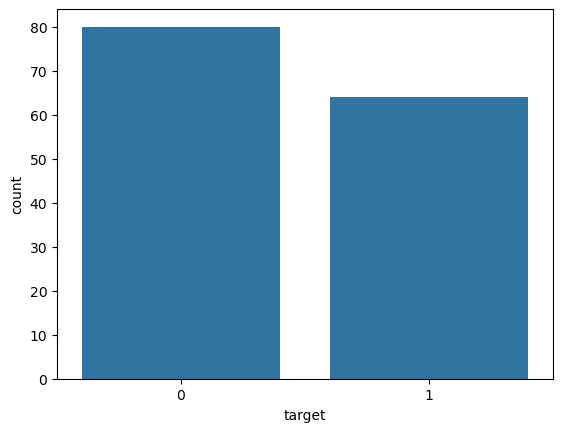

In [72]:
sns.countplot(x="target", data=train)
plt.show()

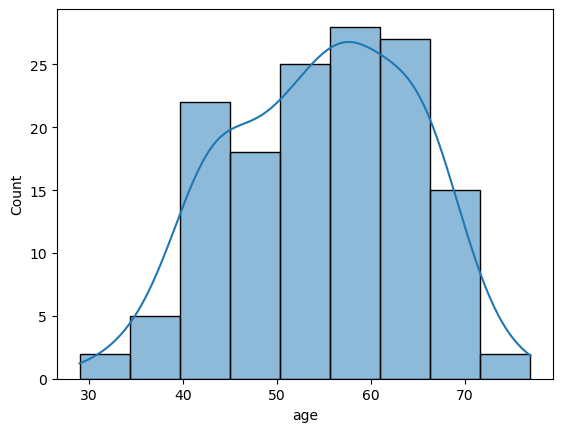

In [73]:
sns.histplot(train["age"], kde=True)
plt.show()

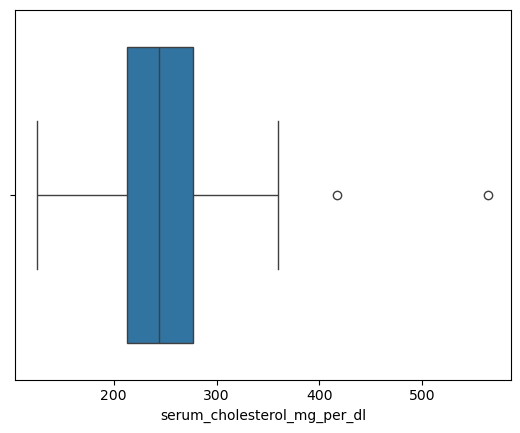

In [74]:
sns.boxplot(x=train["serum_cholesterol_mg_per_dl"])
plt.show()

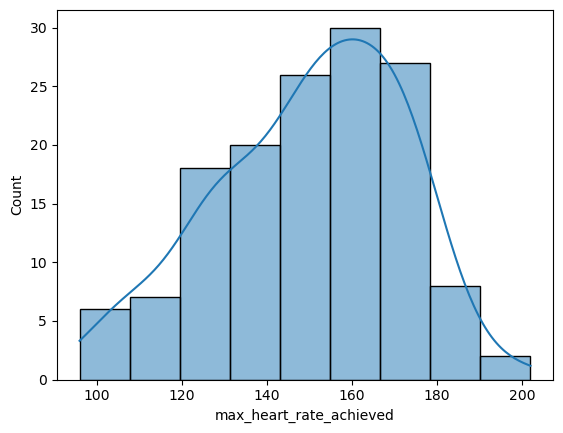

In [75]:
sns.histplot(train["max_heart_rate_achieved"], kde=True)
plt.show()

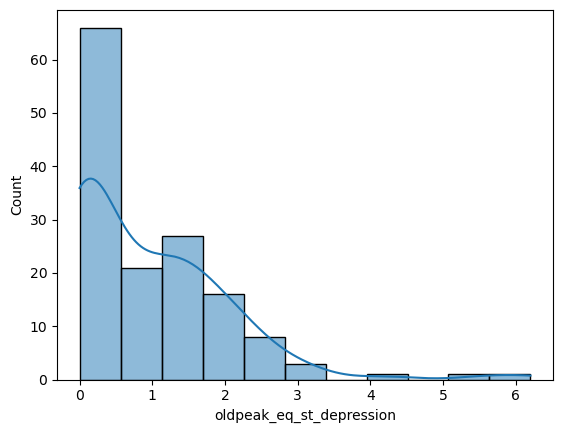

In [76]:
sns.histplot(train["oldpeak_eq_st_depression"], kde=True)
plt.show()

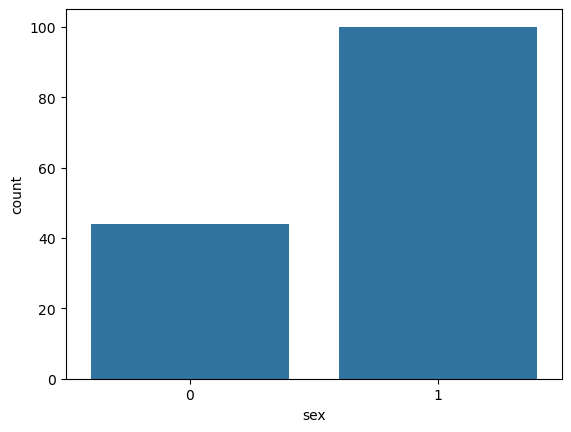

In [77]:
sns.countplot(x="sex", data=train)
plt.show()

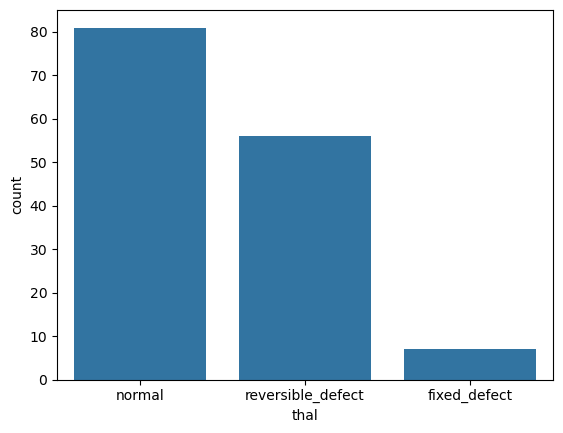

In [78]:
sns.countplot(x="thal", data=train)
plt.show()

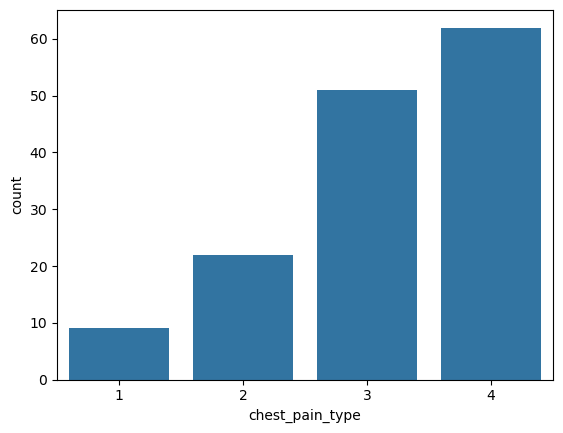

In [79]:
sns.countplot(x="chest_pain_type", data=train)
plt.show()

## Bivariate

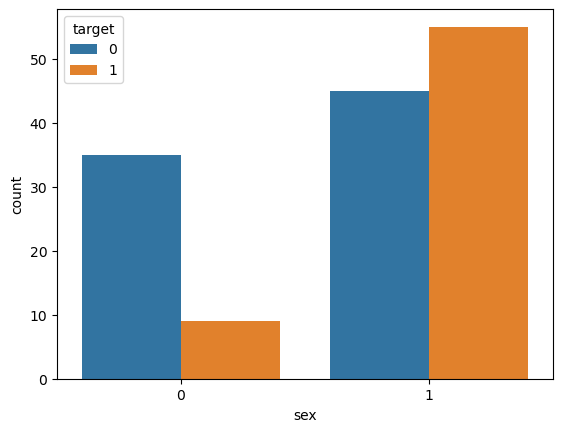

In [80]:
sns.countplot(x="sex", hue="target", data=train)
plt.show()

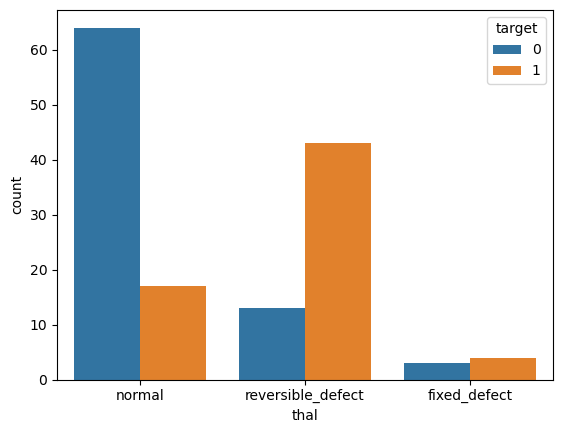

In [81]:
sns.countplot(x="thal", hue="target", data=train)
plt.show()

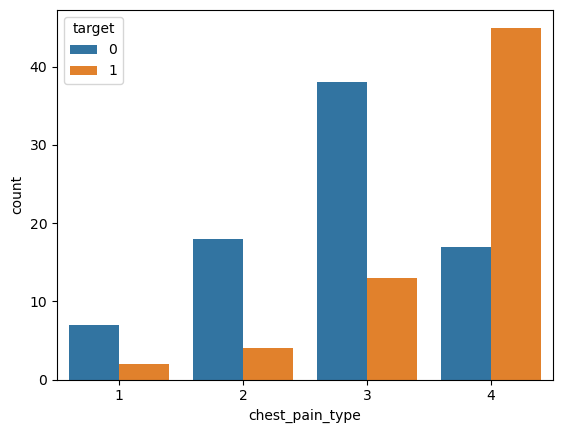

In [82]:
sns.countplot(x="chest_pain_type", hue="target", data=train)
plt.show()

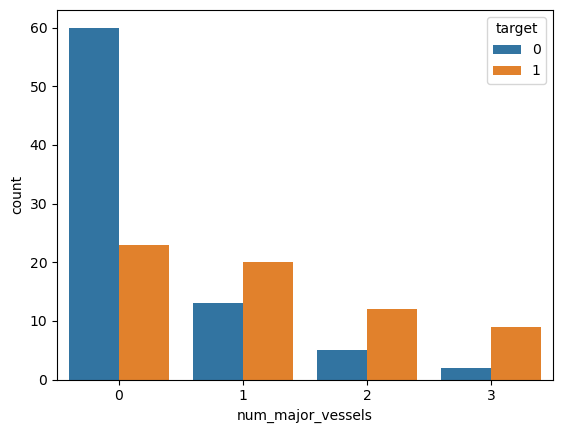

In [83]:
sns.countplot(x="num_major_vessels", hue="target", data=train)
plt.show()

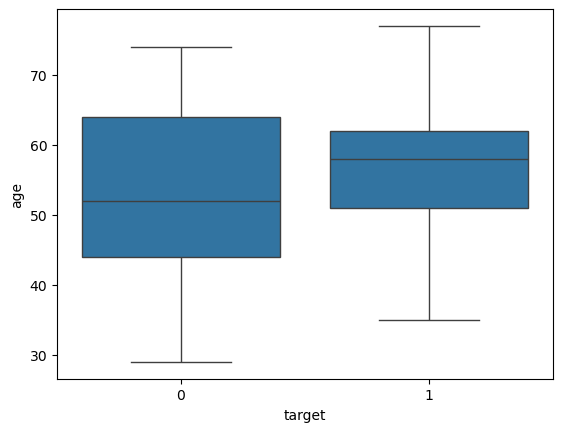

In [84]:
sns.boxplot(x="target", y="age", data=train)
plt.show()

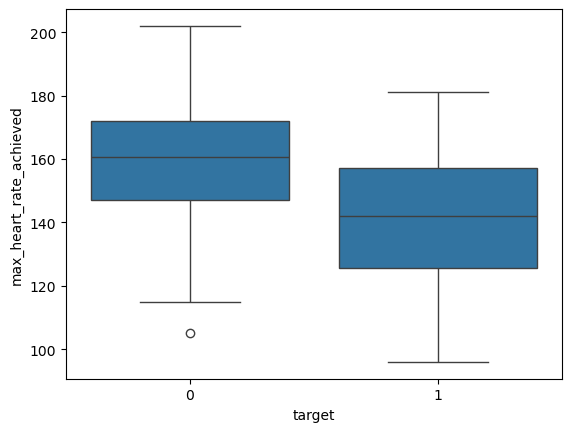

In [85]:
sns.boxplot(x="target", y="max_heart_rate_achieved", data=train)
plt.show()

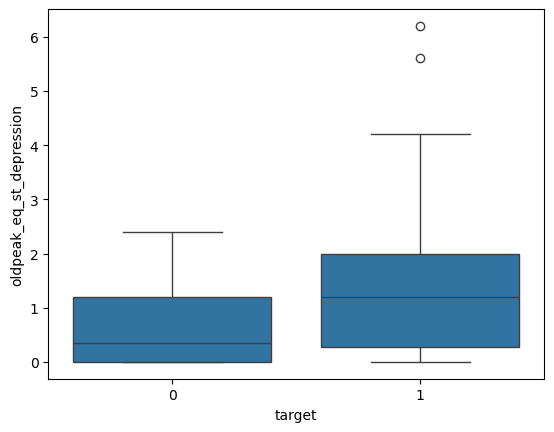

In [86]:
sns.boxplot(x="target", y="oldpeak_eq_st_depression", data=train)
plt.show()

## heat map

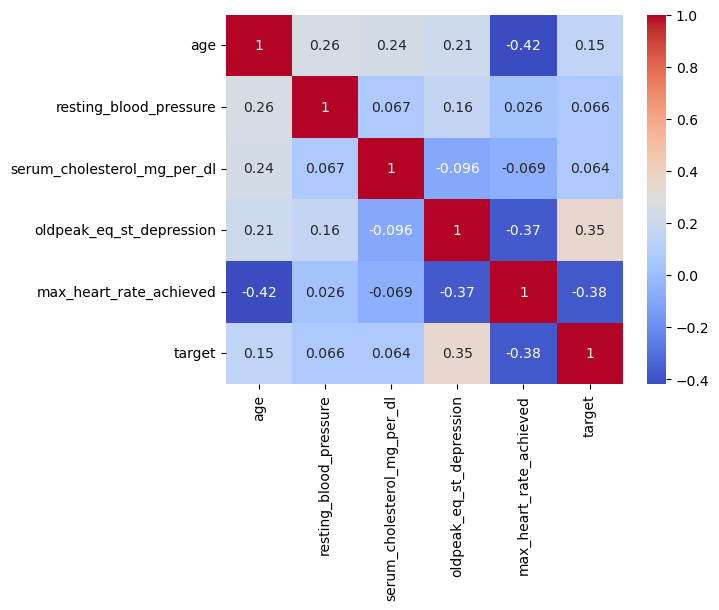

In [87]:
sns.heatmap(train[num_cols + ["target"]].corr(), annot=True, cmap="coolwarm")
plt.show()

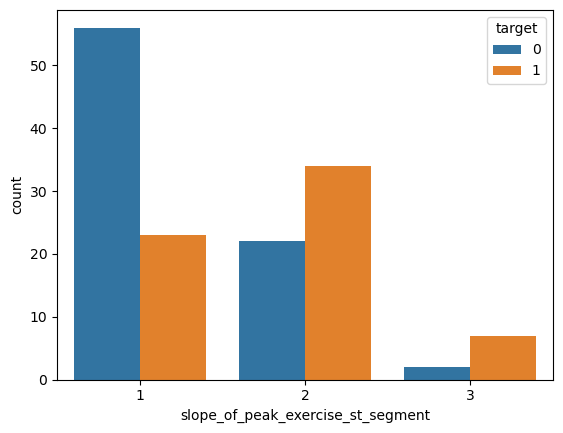

In [88]:
sns.countplot(x="slope_of_peak_exercise_st_segment", hue="target", data=train)
plt.show()

## scaling and encodeing 

In [93]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

prep_scaled = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin"  , "passthrough", bin_cols),
])

prep_trees = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("rest", "passthrough", num_cols + bin_cols),
])

## metrics 

In [96]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, roc_auc_score, recall_score, f1_score
results = {}

def evaluate(name, clf, prep):
    pipe = Pipeline([("prep", prep), ("clf", clf)])
    s = cross_validate(pipe, x_train, y_train, cv=cv, scoring=scoring)
    results[name] = {
        "AUC": s["test_roc_auc"].mean(),
        "Recall": s["test_recall"].mean(),
        "F1": s["test_f1"].mean(),
        "Accuracy": s["test_accuracy"].mean(),
        "AUC std": s["test_roc_auc"].std(),
    }

## models 

In [99]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scoring = ["roc_auc", "recall", "f1", "accuracy"]


evaluate("Logistic Regression", LogisticRegression(max_iter=1000), prep_scaled)
evaluate("KNN", KNeighborsClassifier(), prep_scaled)
evaluate("SVM", SVC(), prep_scaled)

evaluate("Decision Tree", DecisionTreeClassifier(max_depth=3, random_state=42), prep_trees)
evaluate("Random Forest", RandomForestClassifier(random_state=42), prep_trees)
evaluate("Gradient Boosting", GradientBoostingClassifier(random_state=42), prep_trees)


  File "c:\Users\umar ayaan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\umar ayaan\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\umar ayaan\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\umar ayaan\anaco

In [100]:
comparison = pd.DataFrame(results).T.sort_values("AUC", ascending=False).round(3)
comparison

,AUC,Recall,F1,Accuracy,AUC std
Random Forest,0.861,0.735,0.749,0.778,0.058
Logistic Regression,0.859,0.755,0.777,0.806,0.057
SVM,0.853,0.723,0.740,0.778,0.068
Gradient Boosting,0.830,0.703,0.706,0.745,0.042
KNN,0.810,0.650,0.687,0.743,0.062
Decision Tree,0.735,0.678,0.670,0.713,0.070


## hyperparameter Tuning

In [101]:
from sklearn.model_selection import GridSearchCV

tuned = {}

def tune(name, clf, prep, grid):
    pipe = Pipeline([("prep", prep), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(x_train, y_train)
    tuned[name] = gs
    print(name, "| best CV AUC:", round(gs.best_score_, 3))
    print("   ", gs.best_params_)

tune("Logistic Regression", LogisticRegression(max_iter=1000), prep_scaled,
     {"clf__C": [0.01, 0.1, 1, 10],
      "clf__class_weight": [None, "balanced"]})

tune("SVM", SVC(probability=True), prep_scaled,
     {"clf__C": [0.1, 1, 10],
      "clf__gamma": ["scale", 0.01, 0.1],
      "clf__class_weight": [None, "balanced"]})

tune("Random Forest", RandomForestClassifier(random_state=42), prep_trees,
     {"clf__n_estimators": [200, 500],
      "clf__max_depth": [3, 5, None],
      "clf__min_samples_leaf": [1, 3, 5]})

Logistic Regression | best CV AUC: 0.878
    {'clf__C': 0.1, 'clf__class_weight': None}
SVM | best CV AUC: 0.882
    {'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__gamma': 0.01}
Random Forest | best CV AUC: 0.884
    {'clf__max_depth': 5, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 500}


In [102]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import joblib

final_model = tuned["Logistic Regression"].best_estimator_   # simplest and most explainable of the tied top three

pred = final_model.predict(x_test)
proba = final_model.predict_proba(x_test)[:, 1]

print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))
print("Test ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

joblib.dump(final_model, "heart_logreg.pkl")

              precision    recall  f1-score   support

           0       0.89      0.85      0.87        20
           1       0.82      0.88      0.85        16

    accuracy                           0.86        36
   macro avg       0.86      0.86      0.86        36
weighted avg       0.86      0.86      0.86        36

[[17  3]
 [ 2 14]]
Test ROC-AUC: 0.962


['heart_logreg.pkl']

## report

# Report: Challenges Faced and Techniques Used

**Project:** Heart Disease Prediction | **Dataset:** 180 patients, 13 clinical features | **Task:** Binary classification

## Challenges on the Data and Techniques Used

| # | Challenge | Technique used | Reason |
|---|-----------|----------------|--------|
| 1 | Features and labels were in two separate files (`values.csv`, `labels.csv`) | Merged on `patient_id` (inner join) and checked the shape (180, 15) | Joining by row order can silently attach wrong labels to patients. Joining by ID guarantees correct alignment. |
| 2 | `patient_id` is an identifier, not a medical feature | Dropped it before modeling | An ID carries no information, and a model could memorise it. |
| 3 | Mixed feature types, including a text column (`thal`) and numeric codes that are really categories (`chest_pain_type`, `num_major_vessels`, etc.) | Split columns into numeric, categorical and binary groups. Used one-hot encoding for categorical and scaling for numeric, with binary columns passed through | Models need numbers. One-hot encoding stops the model treating category codes as ordered values. |
| 4 | Data quality: possible missing values, duplicates, or impossible values | Checked nulls, duplicates (on features, excluding ID) and min/max values | No missing values or duplicates were found, and there were no impossible zeros (minimum cholesterol 126, minimum blood pressure 94). No imputation was needed. |
| 5 | Outliers and skew: cholesterol up to 564, and `oldpeak` is skewed with extreme values of 5.6 and 6.2 | Kept the outliers. Used scaling, regularised Logistic Regression and tree-based models | The values are medically plausible, and with only 180 rows deleting data would cost more than it helps. Trees are not sensitive to outliers. |
| 6 | Very small dataset (180 rows, only 36 in the test set), so a single score is noisy | Stratified train/test split and repeated stratified 5-fold cross-validation (3 repeats) | Cross-validation averages many tests and gives a more reliable score than one small test set. |
| 7 | Mild class imbalance (55.6% healthy, 44.4% sick) | `stratify=y` in the split, and evaluated with recall, F1 and ROC-AUC, not just accuracy | Stratifying keeps the class ratio equal in train and test. In a medical problem, missing a sick patient is the costliest error, so recall matters. |
| 8 | Rare category: `fixed_defect` in `thal` has only 8 rows | Kept it, and set `handle_unknown="ignore"` in the encoder | Dropping it loses information, and the setting stops the pipeline crashing on a category missing from one split. |
| 9 | Data leakage risk | Split the data before EDA and preprocessing, and put all preprocessing inside a `Pipeline` | Scaling or encoding on the full data lets test information leak into training and inflates the score. |
| 10 | Different models need different preprocessing | Used two preprocessors: scaled and encoded for Logistic Regression, KNN and SVM; encoded only for tree models | Distance-based and linear models are affected by feature scale, while trees are not. |
| 11 | Overfitting on small data | Limited tree depth, regularisation (`C`) and hyperparameter tuning with `GridSearchCV` on the top 3 models | Constraining flexibility helps models generalise to unseen patients. |

## Key EDA Findings
- Strongest predictors: `thal` (reversible defect), `chest_pain_type` (type 4), `num_major_vessels`, `max_heart_rate_achieved` (lower in sick patients), `oldpeak` and `sex`.
- Weak predictors on their own: `resting_blood_pressure` and `serum_cholesterol` (correlation with the label near 0.06).
- No highly correlated numeric feature pairs (max about 0.42), so no redundancy problem.

## Model Comparison (5-fold x 3 repeated cross-validation)

| Model | AUC | Recall | F1 | Accuracy |
|-------|-----|--------|----|----------|
| Random Forest | 0.861 | 0.735 | 0.749 | 0.778 |
| Logistic Regression | 0.859 | 0.755 | 0.777 | 0.806 |
| SVM | 0.853 | 0.723 | 0.740 | 0.778 |
| Gradient Boosting | 0.830 | 0.703 | 0.706 | 0.745 |
| KNN | 0.810 | 0.650 | 0.687 | 0.743 |
| Decision Tree | 0.735 | 0.678 | 0.670 | 0.713 |

After tuning the top three: Random Forest 0.884, SVM 0.882, Logistic Regression 0.878 (CV AUC).

## Conclusion
The top three models performed almost identically (differences of less than 0.01 AUC, smaller than the fold-to-fold variation of about 0.06), so no single model can be called clearly best on 180 rows. **Logistic Regression** was chosen as the final model because it matched the others on performance, had the best recall and F1 among the untuned models, and is the most interpretable: each feature has a coefficient that explains the prediction.

## Limitations and Future Work
- The dataset is small, so scores are noisy. More patient data would give more reliable results.
- Recall is about 0.75, so roughly 1 in 4 sick patients is missed. Tuning the decision threshold could improve this at the cost of more false alarms.
- The model is a learning project and not a clinical tool.